## Booky: A Bidirectional LSTM Approach to Real-Time Emotion Classification in Narrative Text

> **Final Project by Cristina Kennedy, BSN, RN**
>
> Harvard Extension School<br>
> CSCIE-89B Introduction to Natural Language Processing<br>
> August 2026

## 1.0 Problem Statement
This project explores the extent to which a natural language processing model can automatically detect the emotional tone of a page of narrative text, and whether that detection can be used to create a more expressive and engaging reading experience. This experiment proposes two Bidirectional Long Short Memory (BiLSTM) models to recognize emotions from text. Each BiLSTM uses two LSTMs to train the input data. The first LSTM uses the input data, and the second LSTM uses a reverse representation of the data. The two models were trained to classify nine emotions: "joy", "sadness", "fear", "anger", "surprise", "love", "disgust", "embarrassment", and "curiosity". The winning model was further used to recognize and classify emotions from a well-known narrative text via a kindle-style demo.

> ### Import required libraries

In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from tensorflow.keras import models, layers
import json
import re
import warnings
import urllib.request
import emoji

# set display width for printing
pd.set_option('display.width', 200)

warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)


/opt/anaconda3/envs/CSCIE-89/lib/python3.13/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


## Part 1: Modeling
## 2. Training Data Preparation
The emotion classifier was trained on the GoEmotions(google-research-datasets/go_emotions) dataset that comprises 58,000 Reddit comments manually labeled across 28 emotion categories plus “neutral”, released by Google Research in 2020. The dataset was loaded into a Jupyter notebook via Hugging Face’s dataset library, which conveniently downloads and caches all three already split train, validation, and test sets.

In [2]:
# pip install datasets 

In [3]:
# import `go_emotions` dataset from hugging face
from datasets import load_dataset
data = load_dataset("google-research-datasets/go_emotions", "simplified")
label_names = data["train"].features["labels"].feature.names

# convert to a data frame for visualization purposes
df = data["train"].to_pandas()
df["label_names"] = df["labels"].apply(lambda ids: [label_names[i] for i in ids])
df.head(10)

,text,labels,id,label_names
0,My favourite food is anything I didn't have to...,[27],eebbqej,[neutral]
1,"Now if he does off himself, everyone will thin...",[27],ed00q6i,[neutral]
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj,[anger]
3,To make her feel threatened,[14],ed7ypvh,[fear]
4,Dirty Southern Wankers,[3],ed0bdzj,[annoyance]
5,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,[26],edvnz26,[surprise]
6,Yes I heard abt the f bombs! That has to be wh...,[15],ee3b6wu,[gratitude]
7,We need more boards and to create a bit more s...,"[8, 20]",ef4qmod,"[desire, optimism]"
8,Damn youtube and outrage drama is super lucrat...,[0],ed8wbdn,[admiration]
9,It might be linked to the trust factor of your...,[27],eczgv1o,[neutral]


In [4]:
# project constants
VOCAB_SIZE = 10000
SEQ_LEN = 100
WORDS_PER_PAGE = 130
# 9 emotions out of 28 available are used
EMOTION_LABELS = ["joy", "sadness", "fear", "anger", "surprise", "love", "disgust", "embarrassment", "curiosity"]

Some of the rows have more than one label. One classifier will be trained on single-label rows, and the other will be trained on both single-label and multi-label rows, using only the emotions pre-selected in *EMOTION_LABELS*. The following functions prepare two versions of the data and prepare the training and validation sets. The two models will share the same test set.

In [5]:
# load ONLY with a single emotion tag, and drop the rest
# emotion needs to be present in [emotion_labels]
def load_single_label(split):
    df = data[split].to_pandas()
    mask = df["labels"].apply(len) == 1
    single = df[mask].copy()
    single["label_name"] = single["labels"].apply(lambda x: label_names[x[0]])
    # filter by my emotions
    mask = single["label_name"].isin(EMOTION_LABELS)
    filtered = single[mask].copy()
    filtered["label"] = filtered["label_name"].apply(EMOTION_LABELS.index)
    return filtered[["text", "label", "label_name"]].reset_index(drop=True)

# load rows with one or multiple emotion tags 
# as long as emotion is present in [emotion_labels]
def load_multilabel(split):
    df = data[split].to_pandas()

    # filter by my emotions; convert to multi_hot vector
    df["multi_hot"] = df["labels"]
    for idx, label_ids in df["labels"].items():
        names = [label_names[i] for i in label_ids]
        new_idx = [EMOTION_LABELS.index(n) for n in names if n in EMOTION_LABELS]
        vec = np.zeros(len(EMOTION_LABELS), dtype="float32")
        vec[new_idx] = 1.0
        df.at[idx, "multi_hot"] = vec
    mask = df["multi_hot"].apply(lambda v: any(v))
    filtered = df[mask].copy()
    return filtered[["text", "multi_hot"]].reset_index(drop=True)

# train/val sets for single label data
single_train = load_single_label("train")
single_val = load_single_label("validation")

# train/val set for multi label data
multi_train = load_multilabel("train")
multi_val = load_multilabel("validation")

# test set is same for both models
single_test = load_single_label("test")

print("Single-label train:", len(single_train), "val:", len(single_val), "test:", len(single_test))
print("Multi-label train:", len(multi_train), "val:", len(multi_val))

Single-label train: 7362 val: 870 test: 913
Multi-label train: 10911 val: 1310


Over 80% of the data was lost by dropping the rest of the emotions. However, I have decided to pick just the ones that are encountered more often in narative prose. Next, let's visualize the emotion class distribution across the data. 

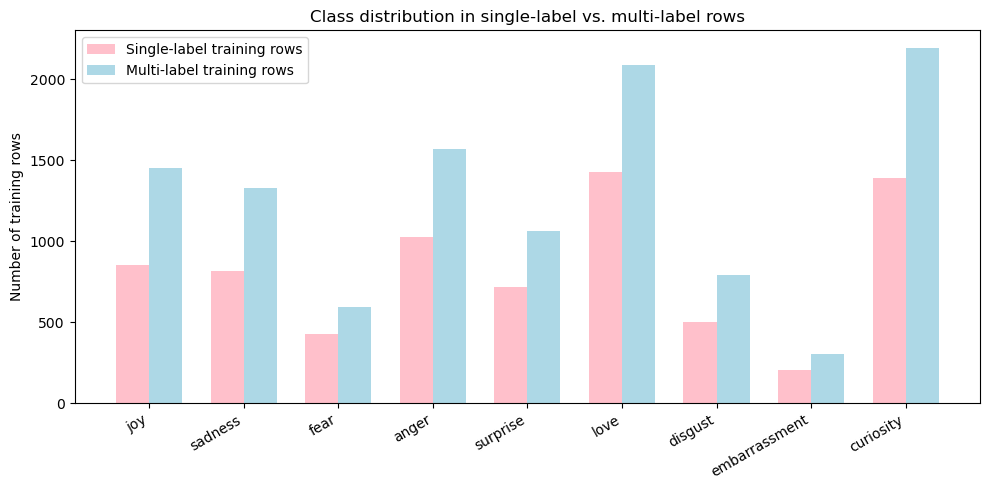

In [6]:
# check class distribution across emotions
# per-class row counts for both training sets
single_counts = single_train["label_name"].value_counts().reindex(EMOTION_LABELS, fill_value=0)
multi_counts = pd.Series(
    np.stack(multi_train["multi_hot"].to_numpy()).sum(axis=0),
    index=EMOTION_LABELS,
)
x = np.arange(len(EMOTION_LABELS))
width = 0.35
# plot emotions distribution by number of rows 
plt.figure(figsize=(10, 5))
plt.bar(x - width/2, single_counts.values, width, color="pink", label="Single-label training rows")
plt.bar(x + width/2, multi_counts.values, width, color="lightblue", label="Multi-label training rows")
plt.xticks(x, EMOTION_LABELS, rotation=30, ha="right")
plt.ylabel("Number of training rows")
plt.title("Class distribution in single-label vs. multi-label rows")
plt.legend()
plt.tight_layout()
plt.show()

There is a class imbalance worth noting. Curiosity and love are the most predominant emotions in the dataset, with anger and joy following closely. Embarrassment and fear are the least common emotions. This spread is not surprising given that the data originates from Reddit posts, but I would expect this class imbalance to be a potential issue when this classifier is later applied to a narrative text. 

Another thing that needs to be addressed is that the data contains a lot of emojis that are unlikely to appear in narrative text, so they will need to be dropped.

In [7]:
# pip install emoji

In [8]:
# strip emojis
import emoji

def strip_emojis(text: str) -> str:
    """Removes emoji characters using the `emoji` library"""
    return emoji.replace_emoji(text, replace="")
# remove emojis from every dataframe
for df in (single_train, single_val, single_test, multi_train, multi_val):
    df["text"] = df["text"].apply(strip_emojis)

Further data processing includes "translating" or vectorizing the data. For this step, I opted for the Keras TextVectorization, which will later be passed on as a Keras layer and will serve as input for the Embedding layer in the model building pipeline.

In [9]:
# shared vectorizer for single label and multi label data
vectorizer = layers.TextVectorization(max_tokens=VOCAB_SIZE, output_sequence_length=SEQ_LEN)
vectorizer.adapt(tf.constant(pd.concat([single_train["text"], multi_train["text"]]).tolist()))

## 3.0. Model Architecture and Training

In [10]:
EPOCHS = 25
PATIENCE = 3
BATCH_SIZE = 64

### 3.1.Model A
The first model is Model A trained on single-label data and has a softmax activation function. EarlyStopping on validation accuracy is used as a regularization technique to stop training once it stops improving after three epochs.

In [11]:
# Model A architecture
model_A = models.Sequential([
    vectorizer,
    layers.Embedding(VOCAB_SIZE, 64),
    layers.Bidirectional(layers.LSTM(48)),
    layers.Dense(48, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(EMOTION_LABELS), activation="softmax"),
])
model_A.compile(optimizer="adam",
                       loss="sparse_categorical_crossentropy",
                       metrics=["accuracy"])

In [12]:
# the train/val data are still pd dataframes, so they need to be converted to the format expected by TextVectorization
# converts text into tensors and labels into np.array for training purposes
x_train = tf.constant(single_train["text"].tolist())
y_train = single_train["label"].to_numpy()
x_val = tf.constant(single_val["text"].tolist())
y_val = single_val["label"].to_numpy()

# add early stopping to prevent overfitting
early_stop = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=PATIENCE, restore_best_weights=True)

history_A = model_A.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2,
)

Epoch 1/25
116/116 - 4s - 36ms/step - accuracy: 0.2499 - loss: 2.0506 - val_accuracy: 0.3494 - val_loss: 1.7976
Epoch 2/25
116/116 - 4s - 38ms/step - accuracy: 0.3951 - loss: 1.6881 - val_accuracy: 0.4805 - val_loss: 1.5265
Epoch 3/25
116/116 - 5s - 39ms/step - accuracy: 0.5049 - loss: 1.4162 - val_accuracy: 0.5149 - val_loss: 1.3916
Epoch 4/25
116/116 - 5s - 40ms/step - accuracy: 0.6229 - loss: 1.1095 - val_accuracy: 0.5885 - val_loss: 1.2746
Epoch 5/25
116/116 - 5s - 40ms/step - accuracy: 0.7111 - loss: 0.8581 - val_accuracy: 0.6402 - val_loss: 1.2461
Epoch 6/25
116/116 - 5s - 40ms/step - accuracy: 0.7946 - loss: 0.6598 - val_accuracy: 0.6322 - val_loss: 1.4592
Epoch 7/25
116/116 - 5s - 42ms/step - accuracy: 0.8469 - loss: 0.5123 - val_accuracy: 0.6552 - val_loss: 1.3942
Epoch 8/25
116/116 - 5s - 41ms/step - accuracy: 0.8851 - loss: 0.4039 - val_accuracy: 0.6471 - val_loss: 1.5385
Epoch 9/25
116/116 - 5s - 40ms/step - accuracy: 0.9197 - loss: 0.3038 - val_accuracy: 0.6460 - val_loss:

In [13]:
model_A.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 96)             │        43,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 48)             │         4,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │           441 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,065,469 (7.88 MB)

 Trainable params: 688,489 (2.63 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,376,980 (5.25 MB)

### 3.2. Model B
Model B has the same architecture as Model A, except it's trained on the multi-label data and has a sigmoid activation function since each of the 9 emotions gets an independent probability that does not need to sum to 1. The loss function is binary_crossentropy instead of sparse_categorical_crossentropy.

In [14]:
model_B = models.Sequential([
    vectorizer,
    layers.Embedding(VOCAB_SIZE, 64),
    layers.Bidirectional(layers.LSTM(48)),
    layers.Dense(48, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(EMOTION_LABELS), activation="sigmoid"),
])

model_B.compile(optimizer="adam",
                       loss="binary_crossentropy",
                       metrics=["binary_accuracy"])

# convert text into tensors and labels into np.array for training purposes
x_train_B = tf.constant(multi_train["text"].tolist())
y_train_B = np.stack(multi_train["multi_hot"].to_numpy())
x_val_B = tf.constant(multi_val["text"].tolist())
y_val_B = np.stack(multi_val["multi_hot"].to_numpy())

# add early stopping to prevent overfitting
early_stop_B = keras.callbacks.EarlyStopping(monitor="val_binary_accuracy", patience=PATIENCE, restore_best_weights=True)
# fit model
history_B = model_B.fit(
    x_train_B, y_train_B,
    validation_data=(x_val_B, y_val_B),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2,
)

Epoch 1/25
171/171 - 7s - 40ms/step - binary_accuracy: 0.8484 - loss: 0.4162 - val_binary_accuracy: 0.8942 - val_loss: 0.3170
Epoch 2/25
171/171 - 7s - 41ms/step - binary_accuracy: 0.8961 - loss: 0.3173 - val_binary_accuracy: 0.9070 - val_loss: 0.2696
Epoch 3/25
171/171 - 7s - 40ms/step - binary_accuracy: 0.9070 - loss: 0.2655 - val_binary_accuracy: 0.9118 - val_loss: 0.2318
Epoch 4/25
171/171 - 7s - 40ms/step - binary_accuracy: 0.9214 - loss: 0.2147 - val_binary_accuracy: 0.9216 - val_loss: 0.2088
Epoch 5/25
171/171 - 7s - 40ms/step - binary_accuracy: 0.9376 - loss: 0.1780 - val_binary_accuracy: 0.9261 - val_loss: 0.2082
Epoch 6/25
171/171 - 7s - 40ms/step - binary_accuracy: 0.9479 - loss: 0.1506 - val_binary_accuracy: 0.9267 - val_loss: 0.2066
Epoch 7/25
171/171 - 7s - 41ms/step - binary_accuracy: 0.9548 - loss: 0.1308 - val_binary_accuracy: 0.9261 - val_loss: 0.2187
Epoch 8/25
171/171 - 7s - 41ms/step - binary_accuracy: 0.9601 - loss: 0.1161 - val_binary_accuracy: 0.9283 - val_loss:

### 3.3. Model Evaluation
Both models are evaluated on the exact same single-label test set *single_test*. Regardless of how each model produces its output, the question it's answering is the same: does the predicted label match the ground truth?


In [15]:
# first, same conversion from pd to string tensors/np.arrays
x_test = tf.constant(single_test["text"].tolist())
y_test = single_test["label"].to_numpy()

# model A predictions on test data 
probs_a = model_A.predict(x_test, verbose=0)
pred_a = probs_a.argmax(axis=1)
# model A accuracy (predicted vs. ground truth labels)
acc_a = (pred_a == y_test).mean()

# model A predictions on test data 
probs_b = model_B.predict(x_test, verbose=0)
pred_b = probs_b.argmax(axis=1)
# model A accuracy (predicted vs. ground truth labels)
acc_b = (pred_b == y_test).mean()

# calculate and display the overall model accuracy
print(f"Model A (single-label, softmax) overall accuracy: {acc_a:.2f}")
print(f"Model B (multi-label,  sigmoid ) overall accuracy: {acc_b:.2f}")
print()

# print accuracies per class for each model, with n as the number of test rows for a specific emotion 
header = "Emotion", "n", "A acc", "B acc"
print(f"{header[0]:14s} {header[1]:>4s}  {header[2]:>7s}  {header[3]:>7s}")
for i, label in enumerate(EMOTION_LABELS):
    mask = y_test == i
    n = mask.sum()
    if n > 0:
        print(f"{label:14s} {n:4d}  {(pred_a[mask]==i).mean():7.2f}  {(pred_b[mask]==i).mean():7.2f}")

# pick winning model to be used for demo based on highest overall accuracy 
if acc_a >= acc_b:
    winner_name, emotion_model, test_acc = "Model A (single-label, softmax)", model_A, acc_a
else:
    winner_name, emotion_model, test_acc = "Model B (multi-label, sigmoid)", model_B, acc_b
print()
print(f"Winner: {winner_name}.")

Model A (single-label, softmax) overall accuracy: 0.63
Model B (multi-label,  sigmoid ) overall accuracy: 0.69

Emotion           n    A acc    B acc
joy              93     0.75     0.70
sadness         102     0.67     0.75
fear             65     0.38     0.75
anger           131     0.51     0.63
surprise         87     0.49     0.53
love            160     0.92     0.89
disgust          76     0.43     0.53
embarrassment    23     0.04     0.48
curiosity       176     0.68     0.68

Winner: Model B (multi-label, sigmoid).


Model A best val accuracy: 0.66
Model B best val accuracy: 0.93


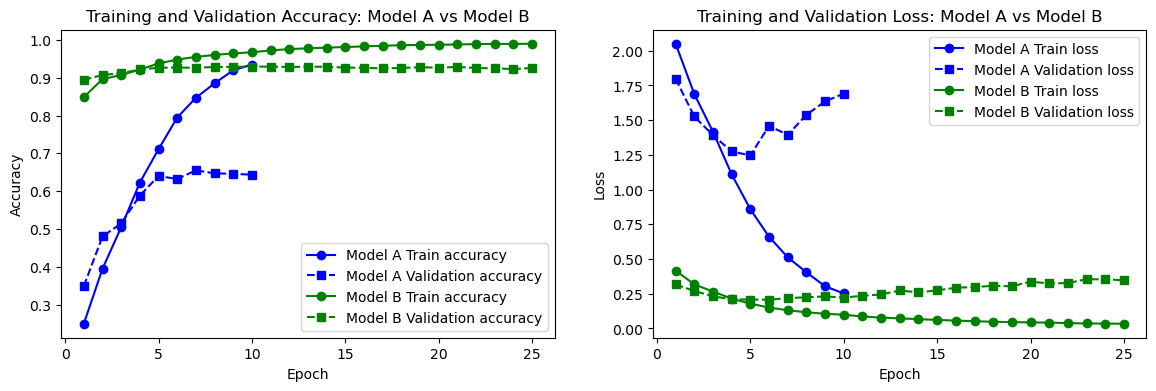

In [16]:
# model A per epoch train and val accuracy/loss
acc_a, val_acc_a = history_A.history['accuracy'], history_A.history['val_accuracy']
loss_a, val_loss_a = history_A.history['loss'], history_A.history['val_loss']
epochs_a = range(1, len(acc_a) + 1)
print(f"Model A best val accuracy: {max(val_acc_a):.2f}")

# model A per epoch train and val accuracy
acc_b, val_acc_b = history_B.history['binary_accuracy'], history_B.history['val_binary_accuracy']
loss_b, val_loss_b = history_B.history['loss'], history_B.history['val_loss']
epochs_b = range(1, len(acc_b) + 1)
print(f"Model B best val accuracy: {max(val_acc_b):.2f}")

# plot train/val accuracy and loss curves for both models over epochs
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
metrics = [
    (axes[0], acc_a, val_acc_a, acc_b, val_acc_b, "Training and Validation Accuracy: Model A vs Model B", "Accuracy"),
    (axes[1], loss_a, val_loss_a, loss_b, val_loss_b, "Training and Validation Loss: Model A vs Model B", "Loss"),
]
for ax, train_a, val_a, train_b, val_b, title, ylabel in metrics:
    ax.plot(epochs_a, train_a, 'bo-', label=f"Model A Train {ylabel.lower()}")
    ax.plot(epochs_a, val_a, 'bs--', label=f"Model A Validation {ylabel.lower()}")
    ax.plot(epochs_b, train_b, 'go-', label=f"Model B Train {ylabel.lower()}")
    ax.plot(epochs_b, val_b, 'gs--', label=f"Model B Validation {ylabel.lower()}")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
plt.show()

In [17]:
from sklearn.metrics import classification_report, confusion_matrix

# pull and print evaluation metrics for model A
print("Model A: precision / recall / F1")
print(classification_report(y_test, pred_a, target_names=EMOTION_LABELS, zero_division=0))
# pull and print evaluation metrics for model A
print("Model B: precision / recall / F1")
print(classification_report(y_test, pred_b, target_names=EMOTION_LABELS, zero_division=0))

Model A: precision / recall / F1
               precision    recall  f1-score   support

          joy       0.69      0.75      0.72        93
      sadness       0.58      0.67      0.62       102
         fear       0.48      0.38      0.43        65
        anger       0.67      0.51      0.58       131
     surprise       0.48      0.49      0.49        87
         love       0.92      0.92      0.92       160
      disgust       0.38      0.43      0.40        76
embarrassment       0.17      0.04      0.07        23
    curiosity       0.61      0.68      0.64       176

     accuracy                           0.63       913
    macro avg       0.55      0.54      0.54       913
 weighted avg       0.62      0.63      0.62       913

Model B: precision / recall / F1
               precision    recall  f1-score   support

          joy       0.70      0.70      0.70        93
      sadness       0.65      0.75      0.69       102
         fear       0.74      0.75      0.75      

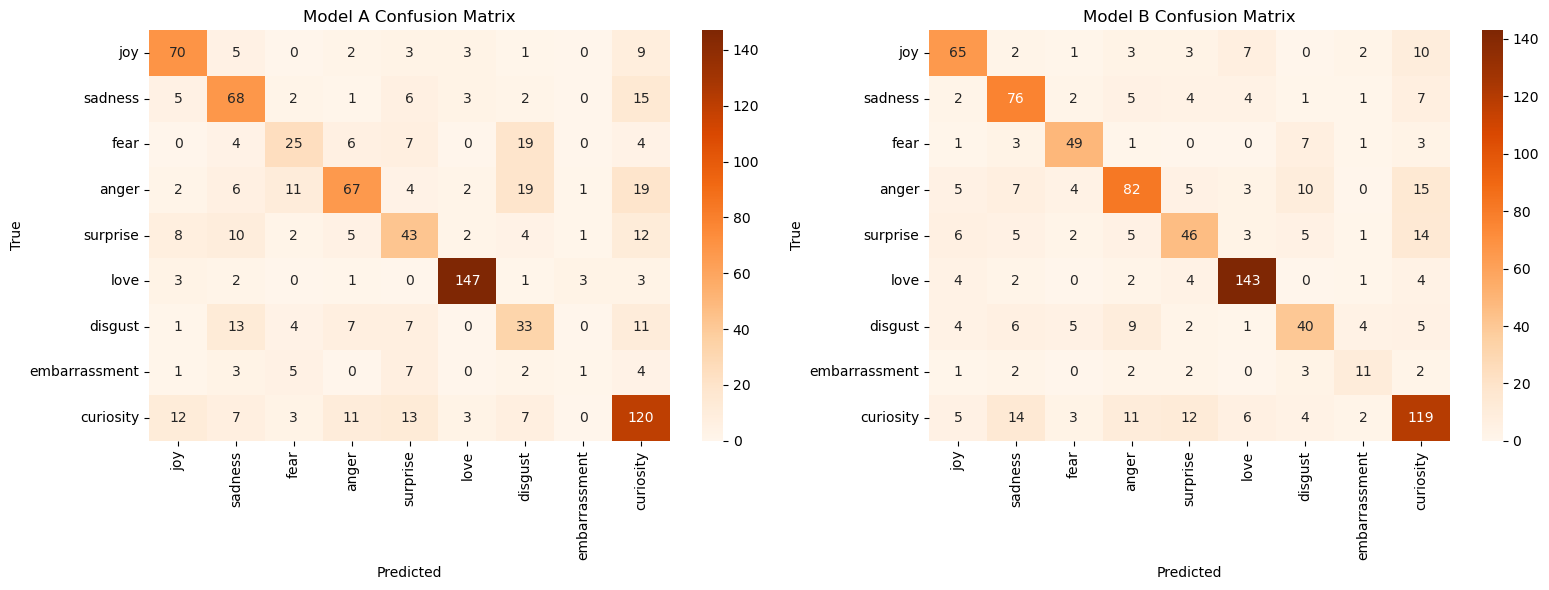

In [20]:
# model A confusion matrix
cm_a = confusion_matrix(y_test, pred_a, labels=range(len(EMOTION_LABELS)))
# model B confusion matrix
cm_b = confusion_matrix(y_test, pred_b, labels=range(len(EMOTION_LABELS)))

# plot Model A and Model B confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# cm for model A
sns.heatmap(cm_a, annot=True, fmt="d", cmap="Oranges",
            xticklabels=EMOTION_LABELS, yticklabels=EMOTION_LABELS, ax=axes[0])
axes[0].set_title("Model A Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
#cm for model B
sns.heatmap(cm_b, annot=True, fmt="d", cmap="Oranges",
            xticklabels=EMOTION_LABELS, yticklabels=EMOTION_LABELS, ax=axes[1])
axes[1].set_title("Model B Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
plt.tight_layout()
plt.show()

It is clear that model B is superior over model A not just based on the overall accuracy (69% vs 64%), but also across almost every individual emotion class. Model B resulted in better precidion, recall and F1 scores across most emotions. It is also worth noting that model A never predicts the emotion *embarasement* correctly, while model B does so about 39% of the time. The confusion matrix suggests that *love* is the easiest emotion to predict correctly, embarassement is the hardest to predicts and both models confuse curiosity and surprise. However, model B is a more accurate classifier regardless.

## 4.0. Part 2: Demo!
 The text I chose to apply the trained model B to is The Wonderful Wizard of Oz by L. Frank Baum (1900), eBook #55 on Project Gutenberg (https://www.gutenberg.org/ebooks/55), which is in the public domain in the United States. 
### 4.1. Load, Clean and Preprocess the Book Text
The book is downloaded as plain text from Project Gutenberg, then everything except the actual novel gets stripped out. That includes the mandatory license text at the start and end of the e-book and removing "[Illustration]" placeholders left over from the original picture captions.


In [21]:
# load and clean the textbook
import urllib.request as _r
if not os.path.exists("oz_raw.txt"):
    _r.urlretrieve("https://www.gutenberg.org/cache/epub/55/pg55.txt", "oz_raw.txt")
with open("oz_raw.txt", encoding="utf-8") as f:
    raw = f.read()

start_marker = "*** START OF THE PROJECT GUTENBERG EBOOK THE WONDERFUL WIZARD OF OZ ***"
end_marker = "*** END OF THE PROJECT GUTENBERG EBOOK THE WONDERFUL WIZARD OF OZ ***"
body = raw.split(start_marker, 1)[1].split(end_marker, 1)[0]
body = body.replace("[Illustration]", "")
print(f"{len(body):,} characters of book text loaded")

207,810 characters of book text loaded


The raw text is then split into chapters by scanning line by line for headings that look like "Chapter IV" on their own line. Each heading gets paired with the subtitle on the next non-blank line (e.g. "Chapter I: The Cyclone"), and all the text between headings gets collected as that chapter's body.
Finally, a cleanup pass collapses extra spaces/tabs down to a single space and excess line-endings down to at most two consecutive line breaks. The result is 24 separated chapters.

>Initially, I attempted an exact string check for the chapter headings, but that wasn't working because the Roman numerals vary across all 24 chapters and there was no single fixed string to match against. I discussed the problem with an LLM, which suggested using regular expression instead. The following block of code has been partially generated with Claude.

In [22]:
# count chapters
lines = body.split("\n")
chapter_heading = re.compile(r"^Chapter [IVXLC]+$")

chapters = []
i = 0
current_title = None
current_lines = []
while i < len(lines):
    line = lines[i].strip()
    if chapter_heading.match(line):
        if current_title:
            chapters.append((current_title, "\n".join(current_lines).strip()))
        j = i + 1
        while j < len(lines) and not lines[j].strip():
            j += 1
        subtitle = lines[j].strip() if j < len(lines) else ""
        current_title = f"{line}: {subtitle}"
        current_lines = []
        i = j + 1
        continue
    current_lines.append(lines[i])
    i += 1
if current_title:
    chapters.append((current_title, "\n".join(current_lines).strip()))

cleaned_chapters = []
for title, text in chapters:
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{2,}", "\n\n", text)
    text = text.strip()
    if text:
        cleaned_chapters.append((title, text))
chapters = cleaned_chapters

print(f"Found {len(chapters)} chapters")

Found 24 chapters


After the text has been cleaned and separated into 24 chapters, it will be paginated into an e-reader style. Each "page" will contain up to 130 words. A new chapter always starts on a new page.  

In [23]:
pages = []
for chap_title, chap_text in chapters:
    words = chap_text.split()
    i = 0
    first_page_of_chapter = True
    while i < len(words):
        chunk = words[i:i + WORDS_PER_PAGE]
        text = " ".join(chunk)
        pages.append({
            "chapter": chap_title,
            "text": text,
            "is_chapter_start": first_page_of_chapter,
        })
        first_page_of_chapter = False
        i += WORDS_PER_PAGE

print(f"Built {len(pages)} pages")

Built 312 pages


### 4.2. Model Inference
Model B will classify and assign each page a label, confidence score, and a probability vector. The emotion labels predicted here will display on the e-reader at the bottom of the page as you are reading through the book.

In [24]:
# Score every page with the winning emotion model
page_texts = tf.constant([p["text"] for p in pages])
page_probs = emotion_model.predict(page_texts, batch_size=64, verbose=0)

for p, probs in zip(pages, page_probs):
    label_idx = int(np.argmax(probs))
    p["emotion_label"] = EMOTION_LABELS[label_idx]
    p["emotion_confidence"] = round(float(probs[label_idx]), 4)
    p["emotion_probs"] = [round(float(x), 4) for x in probs]

# print # of emotion instances
from collections import Counter
Counter(p["emotion_label"] for p in pages)

Counter({'curiosity': 81,
         'anger': 65,
         'love': 51,
         'joy': 33,
         'sadness': 31,
         'surprise': 16,
         'embarrassment': 15,
         'disgust': 10,
         'fear': 10})

One thing that I was interested in was how the emotions fluctuate throughout the book. The chart in Fig. 8. tracks the top five emotions and their predicted probabilities separately across all 312 pages, each smoothed with a 15-page rolling average. [A rolling average](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html) is usually used to smooth a noisy signal by replacing each point with the average of the point and its (in this case 15) neighbors.

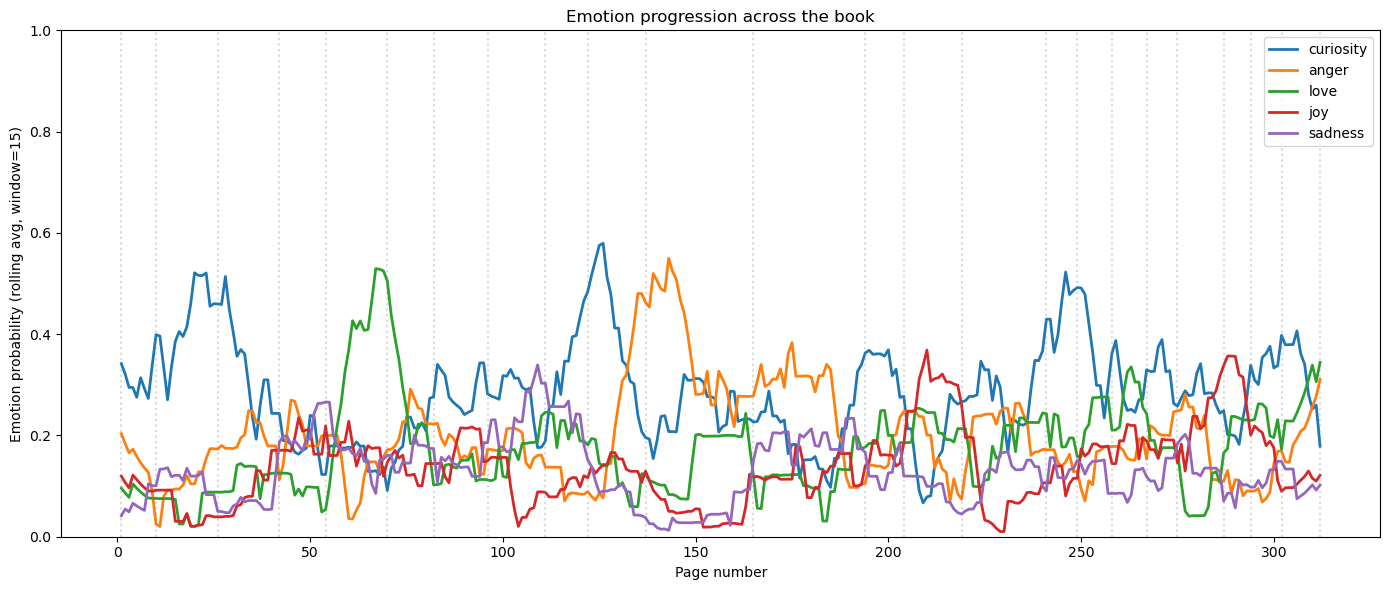

In [25]:
# build a page x emotion probability table
probs_df = pd.DataFrame([p["emotion_probs"] for p in pages], columns=EMOTION_LABELS)
probs_df["chapter"] = [p["chapter"] for p in pages]

# smooth with a rolling average (15 neighbors)
WINDOW = 15
smoothed = probs_df[EMOTION_LABELS].rolling(window=WINDOW, min_periods=1, center=True).mean()

# find top 5 emotions to plot
top_emotions = probs_df[EMOTION_LABELS].mean().sort_values(ascending=False).head(5).index.tolist()
# plot
fig, ax = plt.subplots(figsize=(14, 6))
page_numbers = range(1, len(pages) + 1)
for emotion in top_emotions:
    ax.plot(page_numbers, smoothed[emotion], label=emotion, linewidth=2)
# mark chapter boundaries
chapter_starts = [i + 1 for i, p in enumerate(pages) if p["is_chapter_start"]]
for x in chapter_starts:
    ax.axvline(x=x, color="gray", linestyle=":", alpha=0.3)
ax.set_xlabel("Page number")
ax.set_ylabel(f"Emotion probability (rolling avg, window={WINDOW})")
ax.set_title("Emotion progression across the book")
ax.legend(loc="upper right")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [26]:
# messages to be displayed next to the emotion on the e-reader
EMOTION_MESSAGES = {
    "joy": ["Cute!", "That\'s what I\'m talking about!", "Well, that was fun!", "Yay! Things are looking up!", "Happy dance.", "That made me smile!"],
    "love": ["Cute, cute, cute!", "Aww, how sweet!", "Love this!!", "That\'s lovely."],
    "surprise": ["What just happened?", "That\'s surprising.", "Whoa, didn\'t see that coming!", "Well, that\'s a twist!", "Surprise!"],
    "anger": ["Ooh, that\'s frustrating!", "Not fair!", "Not cool!", "I did not care for this."],
    "fear": ["Oh no!", "Yikes, that\'s scary!", "That gave me chills!", "I don\'t like this."],
    "sadness": ["Aw, that\'s sad", "AWW :(.", "A bit of a downer", "I feel for you.", "Sad :("],
    "disgust": ["Ew, gross!", "Yuck, that\'s unpleasant.", "That\'s a bit icky"],
    "embarrassment": ["Cringe", "Oh, how awkward!", "Yikes, that\'s embarrassing.", "That\'s a bit cringe."],
    "curiosity": ["How interesting!", "Ooh, I wonder what happens next!", "Now that\'s intriguing.", "Hmm, curious indeed."],
}
for i, p in enumerate(pages):
    p["page_number"] = i + 1
    messages = EMOTION_MESSAGES[p["emotion_label"]]
    p["popup_message"] = messages[hash(p["text"]) % len(messages)]

The following cell creates a pages.json file. To view the reader, start up a local web server (`e.g. run  python3 -m http.server 8000`) and then open in a browser (`localhost:8000/reader.html`). 

In [27]:
# export pages in json
with open("pages.json", "w", encoding="utf-8") as f:
    json.dump({
        "title": "The Wonderful Wizard of Oz",
        "author": "L. Frank Baum",
        "emotion_model_name": winner_name,
        "emotion_model_test_accuracy": round(float(test_acc), 4),
        "emotion_labels": EMOTION_LABELS,
        "pages": pages,
    }, f, indent=2)

print("Wrote pages.json")

Wrote pages.json


The reader.html is an HTML, CSS, and JavaScript document that reads from `pages.json`, which contains metadata for the book and a list of pages. Each page has data about the text (chapter title, text, page number, etc) and data from the model (winning emotion, confidence values, etc).  For reference, here's a snippet of the result:

```json
{
  "title": "The Wonderful Wizard of Oz",
  "author": "L. Frank Baum",
  "emotion_model_name": "Model B (multi-label, sigmoid)",
  "emotion_model_test_accuracy": 0.6922,
  "emotion_labels": ["joy","sadness","fear","anger","surprise","love","disgust","embarrassment","curiosity"],
  "pages": [
    {
      "chapter": "Chapter I: The Cyclone",
      "text": "Dorothy lived in the midst... <truncated for sample>",
      "is_chapter_start": true,
      "emotion_label": "joy",
      "emotion_confidence": 0.2912,
      "emotion_probs": [0.2912,0.0924,0.0082,0.049,0.0048,0.2329,0.0567,0.1114,0.0336],
      "page_number": 1,
      "popup_message": "Happy dance."
    },
    ...
}
```

> The reader.html was initially fully generated by Claude, to which I made minor manual changes to better incorporate it in my project.